# 01 Factibilidad

Que fraccion de los valores del model-index aparece en el cuerpo del README.

In [1]:
import re
import pandas as pd
from collections import Counter
from pathlib import Path
from dotenv import load_dotenv

from metric_extraction.data import ref_values
from metric_extraction.download import safe_name
from metric_extraction.evidence import read_body, extract_hits, signature, table_rows
from metric_extraction.gold import gold_tuples, score_hits, value_close

load_dotenv()
READMES = Path("../data/raw/readmes")
df = pd.read_csv("../data/HFCO2_2026.csv", sep=",")

ref = df[df["performance_metrics"].notna()].copy()
ref["vals"] = ref["performance_metrics"].map(ref_values)
ref = ref[ref["vals"].notna()]

print(f"{len(df)} modelos | {len(list(READMES.glob('*.md')))} README en disco | {len(ref)} con referencia")

2057 modelos | 1931 README en disco | 393 con referencia


In [1]:
from dotenv import load_dotenv
import os
load_dotenv()
HF_TOKEN = os.environ["HF_TOKEN"]

In [9]:
import pandas as pd
from pathlib import Path

from metric_extraction.download import safe_name
from metric_extraction.evidence import read_body, extract_hits

READMES = Path("../data/raw/readmes")
df = pd.read_csv("../data/HFCO2_2026.csv", sep=",")

# Modelos con performance_metrics vacío
EMPTY = {"", "[]", "{}", "null", "none", "nan"}
def is_empty(pm):
    return pd.isna(pm) or str(pm).strip().lower() in EMPTY

empty = df[df["performance_metrics"].map(is_empty)]
print(f"{len(empty)} de {len(df)} con performance_metrics vacío")
sample = empty.sample(min(20, len(empty)), random_state=42)

# Evidencia de métricas leyendo el README desde disco
rows = []
for _, r in sample.iterrows():
    p = READMES / f"{safe_name(r['modelId'])}.md"
    if not p.exists():                      # sin README: no cuenta como 0
        rows.append((r["modelId"], None, None, ""))
        continue
    text = read_body(p)
    hits = [h for h in extract_hits(text) if h[0] != "loss"]
    rows.append((r["modelId"], len(hits), len(text),
                 "; ".join(f"{k}={v}" for k, v in hits[:3])))

res = pd.DataFrame(rows, columns=["modelId", "n_hits", "largo_texto", "muestra"])
pd.set_option("display.width", 200, "display.max_colwidth", 70)
print(res.sort_values("n_hits"))

ok = res["n_hits"].notna()
print(f"\nREADME no encontrado: {(~ok).sum()} de {len(res)}")
print(f"Con evidencia de métricas: {(res['n_hits'].fillna(0) > 0).sum()} de {ok.sum()}")
print(f"Control: {res.loc[ok, 'muestra'].nunique()} muestras distintas y "
      f"{res.loc[ok, 'largo_texto'].nunique()} largos de texto distintos entre {ok.sum()} fichas")

1533 de 2057 con performance_metrics vacío
                                                          modelId  n_hits  largo_texto                                         muestra
4                                  DarwinAnim8or/GPT-NoSleep-355m     0.0       1284.0                                                
17                  BrianDsouzaAI/autotrain-tab-multi-92337144714     0.0        689.0                                                
13                       sindri101/radiology-report-en-zh-ft-base     1.0        476.0                                 sacrebleu=23.06
8                       Manolo/autotrain-nl-en-esco-1-78131140807     1.0        195.0                                sacrebleu=28.221
16                              Tritkoman/EnglishtoAncientGreekV4     1.0        194.0                                 sacrebleu=7.006
12                          wangdy/autotrain-godaddy2-38507101578     3.0        587.0                  r2=0.997; mse=0.042; mae=0.081
7   teacooki

In [2]:
import os, pandas as pd
from dotenv import load_dotenv
from metric_extraction.download import download_readmes

load_dotenv()
df = pd.read_csv("../data/HFCO2_2026.csv", sep=",")
status = download_readmes(df["modelId"].tolist(), "../data/raw/readmes",
                          token=os.environ["HF_TOKEN"])
print(status["result"].value_counts())
print(status["http"].value_counts())

100/1931
200/1931
300/1931
400/1931
500/1931
600/1931
700/1931
800/1931
900/1931
1000/1931
1100/1931
1200/1931
1300/1931
1400/1931
1500/1931
1600/1931
1700/1931
1800/1931
1900/1931
1931/1931
result
cached    1931
fail       126
Name: count, dtype: int64
http
200    1931
403      94
404      32
Name: count, dtype: int64


In [2]:
from pathlib import Path
from metric_extraction.evidence import read_body, signature, table_rows
from metric_extraction.download import safe_name

rows = []
for _, r in df.iterrows():
    p = Path("../data/raw/readmes") / f"{safe_name(r['modelId'])}.md"
    if not p.exists():
        continue
    b = read_body(p)
    rows.append((r["modelId"], r["pipeline_tag"], signature(b), table_rows(b)))

sig = pd.DataFrame(rows, columns=["modelId", "pipeline_tag", "firma", "filas_tabla"])
sig["tiene_firma"] = sig["firma"].map(len) > 0
print(f"{sig['tiene_firma'].mean():.1%} de {len(sig)} fichas con alguna métrica")

top = sig.loc[sig["tiene_firma"], "firma"].value_counts()
print(f"{len(top)} firmas distintas")
print((top.cumsum() / top.sum()).head(10).round(2))   # cobertura acumulada
print(sig.groupby("pipeline_tag")["tiene_firma"].agg(["mean", "size"])
         .sort_values("size", ascending=False).head(12))

87.1% de 1931 fichas con alguna métrica
35 firmas distintas
firma
(accuracy, macro f1, macro precision, macro recall, micro f1, micro precision, micro recall, weighted f1, weighted precision, weighted recall)                                                                                                                                        0.28
(accuracy, auc, f1, precision, recall)                                                                                                                                                                                                                                                0.47
(rouge1, rouge2, rougel, rougelsum)                                                                                                                                                                                                                                                   0.62
(accuracy, f1, precision, recall)                                                    

In [3]:
# 1) ¿De qué familias es la referencia?
ref = df[df["performance_metrics"].notna()
         & (df["performance_metrics"].astype(str).str.strip().str.len() > 2)]
print(ref["pipeline_tag"].value_counts().head(8))
print(ref["auto"].value_counts())

# 2) ¿Qué hay en los README de las tareas con 0 %?
import re
zero = sig[sig["pipeline_tag"].isin(["sentence-similarity", "feature-extraction",
                                     "translation", "text-generation"])
           & ~sig["tiene_firma"]].groupby("pipeline_tag").head(2)
for _, r in zero.iterrows():
    b = read_body(Path("../data/raw/readmes") / f"{safe_name(r['modelId'])}.md")
    lines = [l for l in b.splitlines() if re.search(r"\d\.\d{2,}", l)][:6]
    print("=====", r["pipeline_tag"], r["modelId"])
    print("\n".join(l[:140] for l in lines))

pipeline_tag
sentence-similarity     134
text-generation          94
feature-extraction       93
text-classification      77
text-ranking             33
image-classification     32
token-classification     14
summarization            13
Name: count, dtype: int64
auto
False    481
True      43
Name: count, dtype: int64
===== feature-extraction 1aurent/vit_base_patch16_224.owkin_pancancer
  - [Scaling Self-Supervised Learning for Histopathology with Masked Image Modeling](https://www.medrxiv.org/content/10.1101/2023.07.21.2329
@article{Filiot2023.07.21.23292757,
  elocation-id = {2023.07.21.23292757},
  doi          = {10.1101/2023.07.21.23292757},
  url          = {https://www.medrxiv.org/content/early/2023/09/14/2023.07.21.23292757},
  eprint       = {https://www.medrxiv.org/content/early/2023/09/14/2023.07.21.23292757.full.pdf},
===== text-generation Cran-May/mg

===== text-generation CreatedNull/MiniGPT

===== feature-extraction GrishaKushnir/jobbert-onnx
The model was presented in t

In [4]:
from pathlib import Path
from metric_extraction.evidence import read_body
from metric_extraction.download import safe_name
from metric_extraction.data import ref_values, value_in_text

ref = df[df["performance_metrics"].notna()].copy()
ref["vals"] = ref["performance_metrics"].map(ref_values)
ref = ref[ref["vals"].notna()]
print(len(ref), "fichas con valores de referencia")

out = []
for _, r in ref.iterrows():
    p = Path("../data/raw/readmes") / f"{safe_name(r['modelId'])}.md"
    if not p.exists():
        continue
    b = read_body(p)
    found = sum(value_in_text(v, b) for v in r["vals"])
    out.append((r["modelId"], r["pipeline_tag"], r["auto"], len(r["vals"]), found / len(r["vals"])))

cov = pd.DataFrame(out, columns=["modelId", "pipeline_tag", "auto", "n_vals", "frac"])
print(cov["frac"].describe().round(2))
print(f"{(cov['frac'] >= 0.5).mean():.1%} de las fichas con >=50% de sus valores en el cuerpo")
print(cov.groupby("pipeline_tag")["frac"].agg(["median", "size"])
         .sort_values("size", ascending=False).head(8).round(2))

393 fichas con valores de referencia
count    390.00
mean       0.86
std        0.29
min        0.00
25%        0.90
50%        1.00
75%        1.00
max        1.00
Name: frac, dtype: float64
89.7% de las fichas con >=50% de sus valores en el cuerpo
                      median  size
pipeline_tag                      
sentence-similarity     1.00   134
feature-extraction      0.92    92
text-generation         0.56    57
text-ranking            1.00    27
image-classification    1.00    27
text-classification     1.00    27
summarization           0.00    11
token-classification    1.00    10


In [5]:
import random
rng = random.Random(42)
ids = cov["modelId"].tolist()
null = []
for _, r in ref[ref["modelId"].isin(ids)].iterrows():
    other = rng.choice([i for i in ids if i != r["modelId"]])
    b = read_body(Path("../data/raw/readmes") / f"{safe_name(other)}.md")
    null.append(sum(value_in_text(v, b) for v in r["vals"]) / len(r["vals"]))
print(pd.Series(null).describe().round(2))

count    390.00
mean       0.09
std        0.18
min        0.00
25%        0.00
50%        0.00
75%        0.10
max        1.00
dtype: float64


In [2]:
from collections import Counter
from metric_extraction.evidence import read_body, extract_hits
from metric_extraction.gold import gold_tuples, score_hits, value_close, same_metric

rows, miss = [], Counter()
for _, r in ref.iterrows():
    p = Path("../data/raw/readmes") / f"{safe_name(r['modelId'])}.md"
    if not p.exists():
        continue
    gold = gold_tuples(r["performance_metrics"])
    if not gold:
        continue
    hits = [(n, v) for n, v in extract_hits(read_body(p)) if "loss" not in n.lower()]
    rec, n_gold, ok, n_hits = score_hits(hits, gold)
    rows.append((r["modelId"], r["pipeline_tag"], rec, n_gold, ok, n_hits))
    for al, rv in gold:                       # métricas de referencia no recuperadas
        if not any(same_metric(n, al) and value_close(v, rv) for n, v in hits):
            miss[sorted(al)[0]] += 1

sc = pd.DataFrame(rows, columns=["modelId", "pipeline_tag", "rec", "n_gold", "ok", "n_hits"])
tot = sc[["rec", "n_gold", "ok", "n_hits"]].sum()
P, R = tot["ok"] / tot["n_hits"], tot["rec"] / tot["n_gold"]
print(f"{len(sc)} fichas | P={P:.3f}  R={R:.3f}  F1={2*P*R/(P+R):.3f}")

g = sc.groupby("pipeline_tag").agg(cards=("modelId", "size"), rec=("rec", "sum"),
        n_gold=("n_gold", "sum"), ok=("ok", "sum"), n_hits=("n_hits", "sum"))
g["P"] = g["ok"] / g["n_hits"]; g["R"] = g["rec"] / g["n_gold"]
g["F1"] = 2 * g["P"] * g["R"] / (g["P"] + g["R"])
print(g[["cards", "P", "R", "F1"]].sort_values("cards", ascending=False).head(8).round(2))
print(miss.most_common(20))

390 fichas | P=0.990  R=0.801  F1=0.885
                      cards     P     R    F1
pipeline_tag                                 
sentence-similarity     134  0.99  0.71  0.83
feature-extraction       92  1.00  0.94  0.97
text-generation          57  0.19  0.01  0.01
text-ranking             27  1.00  0.37  0.54
image-classification     27  0.70  0.67  0.68
text-classification      27  0.81  0.46  0.59
summarization            11  0.42  0.30  0.35
token-classification     10  0.48  0.87  0.62
[('acc', 150), ('map', 106), ('f1 macro', 99), ('acc norm', 87), ('ndcg at 10', 86), ('map at 10', 85), ('map at 100', 85), ('map at 1000', 85), ('map at 3', 85), ('map at 5', 85), ('mrr at 10', 85), ('mrr at 100', 85), ('mrr at 1000', 85), ('mrr at 20', 85), ('mrr at 3', 85), ('mrr at 5', 85), ('ndcg at 100', 85), ('ndcg at 1000', 85), ('ndcg at 20', 85), ('ndcg at 3', 85)]


In [7]:
rows = []
for _, r in df.iterrows():
    p = READMES / f"{safe_name(r['modelId'])}.md"
    if not p.exists():
        continue
    b = read_body(p)
    rows.append((r["modelId"], r["pipeline_tag"], signature(b), table_rows(b)))

sig = pd.DataFrame(rows, columns=["modelId", "pipeline_tag", "firma", "filas_tabla"])
sig["tiene_firma"] = sig["firma"].map(len) > 0
print(f"{sig['tiene_firma'].mean():.1%} de {len(sig)} fichas con alguna métrica")

top = sig.loc[sig["tiene_firma"], "firma"].value_counts()
print(f"{len(top)} firmas distintas")
print((top.cumsum() / top.sum()).head(10).round(2))
print(sig.groupby("pipeline_tag")["tiene_firma"].agg(["mean", "size"])
         .sort_values("size", ascending=False).head(12))

87.1% de 1931 fichas con alguna métrica
35 firmas distintas
firma
(accuracy, macro f1, macro precision, macro recall, micro f1, micro precision, micro recall, weighted f1, weighted precision, weighted recall)                                                                                                                                        0.28
(accuracy, auc, f1, precision, recall)                                                                                                                                                                                                                                                0.47
(rouge1, rouge2, rougel, rougelsum)                                                                                                                                                                                                                                                   0.62
(accuracy, f1, precision, recall)                                                    

In [9]:
for tag in ["text-generation", "summarization"]:
    for mid in sc[sc.pipeline_tag == tag].modelId.head(3):
        p = Path("../data/raw/readmes") / f"{safe_name(mid)}.md"
        gold = gold_tuples(ref.loc[ref.modelId == mid, "performance_metrics"].iloc[0])
        hits = [(n, v) for n, v in extract_hits(read_body(p)) if "loss" not in n.lower()]
        print(f"\n== {tag} | {mid}")
        print("GOLD:", [(sorted(a)[0], v) for a, v in gold][:6])
        print("HITS:", hits[:8])


== text-generation | Cran-May/mg
GOLD: [('mmlu', 85.45), ('ifeval', 74.22), ('gsm8k (5 shot)', 75.89), ('humaneval', 79.88), ('gpqa', 37.37)]
HITS: []

== text-generation | GuilhermeAumo/Tucano-2b4-Instruct-Q4_K_M-GGUF
GOLD: [('acc', 57.66), ('acc', 39.92), ('acc', 20.43), ('acc', 22.81), ('acc', 24.83), ('f1 macro', 43.39)]
HITS: []

== text-generation | Polygl0t/GigaVerbo-v2-ablation-Synth-1.5B
GOLD: [('acc norm', 32.6), ('acc norm', 43.9), ('acc', 56.1), ('acc', 33.9), ('acc norm', 72.0)]
HITS: []

== summarization | Jacobsith/autotrain-Hello_there-1209845735
GOLD: [('rouge', 38.2084), ('rouge', 12.4744), ('rouge', 21.5536), ('rouge', 34.229), ('loss', 2.0952045917510986)]
HITS: [('rouge1', 38.448), ('rouge2', 10.9), ('rougel', 22.08), ('rougelsum', 33.458)]

== summarization | L-macc/autotrain-Biomedical_sc_summ-1217846144
GOLD: [('rouge', 39.4086), ('rouge', 12.8115), ('rouge', 21.9191), ('rouge', 35.2431), ('loss', 2.2001051902770996)]
HITS: [('rouge1', 38.839), ('rouge2', 10.86

In [4]:
from metric_extraction.evidence import read_body, extract_hits
from metric_extraction.gold import gold_tuples, score_hits

ref_ids = set(ref["modelId"][ref["performance_metrics"].map(lambda x: bool(gold_tuples(x)))])
rows = []
for _, r in df.iterrows():
    p = Path("../data/raw/readmes") / f"{safe_name(r['modelId'])}.md"
    if not p.exists():
        rows.append((r["modelId"], r["pipeline_tag"], "sin README", 0, 0)); continue
    hits = [(n, v) for n, v in extract_hits(read_body(p)) if "loss" not in n.lower()]
    grupo = "referencia" if r["modelId"] in ref_ids else "sin gold"
    ok = 0
    if grupo == "referencia":
        g = gold_tuples(r["performance_metrics"])
        ok = score_hits(hits, g)[0]
    rows.append((r["modelId"], r["pipeline_tag"], grupo, len(hits), ok))

d = pd.DataFrame(rows, columns=["modelId", "tag", "grupo", "n_hits", "gold_recuperadas"])
print(d.groupby("grupo").agg(fichas=("modelId", "size"),
      con_hits=("n_hits", lambda s: (s > 0).sum()),
      con_acierto=("gold_recuperadas", lambda s: (s > 0).sum())))

            fichas  con_hits  con_acierto
grupo                                    
referencia     390       338          323
sin README     126         0            0
sin gold      1541      1387            0


In [6]:
sg = d[(d.grupo == "sin gold") & (d.n_hits > 0)]
partes = [g.sample(min(len(g), max(1, round(35 * len(g) / len(sg)))), random_state=42)
          for _, g in sg.groupby("tag")]
muestra = pd.concat(partes).head(40)

hits_txt = []
for mid in muestra.modelId:
    p = Path("../data/raw/readmes") / f"{safe_name(mid)}.md"
    hs = [(n, v) for n, v in extract_hits(read_body(p)) if "loss" not in n.lower()]
    hits_txt.append("; ".join(f"{n}={v}" for n, v in hs[:8]))

muestra = muestra.assign(url="https://huggingface.co/" + muestra.modelId, hits=hits_txt, juicio="")
Path("../results").mkdir(exist_ok=True)
muestra[["modelId", "tag", "url", "hits", "juicio"]].to_csv("../results/muestra_manual.csv", index=False)
print(len(muestra), muestra.tag.value_counts().to_dict())

36 {'text-classification': 13, 'image-classification': 7, 'summarization': 6, 'token-classification': 3, 'translation': 3, 'tabular-classification': 1, 'tabular-regression': 1, 'text-generation': 1, 'text-ranking': 1}


In [10]:
import importlib, time
import metric_extraction.gold, metric_extraction.rules, metric_extraction.evaluator as ev
for m in (metric_extraction.gold, metric_extraction.rules, ev): importlib.reload(m)
from metric_extraction.rules import build_catalog
from metric_extraction.evaluator import Instance, Configuration
from metric_extraction.gold import gold_tuples
from metric_extraction.evidence import read_body

cards = []
for _, r in ref.iterrows():
    p = Path("../data/raw/readmes") / f"{safe_name(r['modelId'])}.md"
    g = gold_tuples(r["performance_metrics"])
    if p.exists() and g:
        cards.append({"id": r["modelId"], "tag": r["pipeline_tag"], "gold": g, "text": read_body(p)})

cat = build_catalog()
t0 = time.time(); inst = Instance(cards, cat); print(f"{len(cards)} fichas, precálculo {time.time()-t0:.1f}s")

# (a) cada regla sola
res = []
for i, rule in enumerate(cat):
    m = inst.evaluate(Configuration((i,), 100.0)); res.append((rule.name, i, m["P"], m["R"], m["F1"], m["macro_F1"]))
print(pd.DataFrame(res, columns=["regla", "i", "P", "R", "F1", "macroF1"]).sort_values("macroF1", ascending=False).round(3).head(10))

# (b) todas las reglas, y theta
for th in (1.0, 100.0, 1000.0):
    print(th, {k: round(v, 3) for k, v in inst.evaluate(Configuration(tuple(range(len(cat))), th)).items()})

390 fichas, precálculo 58.2s
         regla   i      P      R     F1  macroF1
7      row:ret   7  1.000  0.741  0.851    0.158
1   inline:ret   1  0.991  0.320  0.483    0.147
0   inline:clf   0  0.826  0.010  0.020    0.079
12  column:clf  12  0.575  0.002  0.004    0.070
6      row:clf   6  0.907  0.009  0.018    0.046
3   inline:gen   3  0.394  0.001  0.001    0.025
15  column:gen  15  0.750  0.000  0.001    0.024
8      row:sim   8  1.000  0.043  0.082    0.020
2   inline:sim   2  1.000  0.042  0.080    0.017
13  column:ret  13  1.000  0.000  0.000    0.002
1.0 {'P': 0.982, 'R': 0.373, 'F1': 0.541, 'macro_F1': 0.288, 'time': 0.149}
100.0 {'P': 0.978, 'R': 0.374, 'F1': 0.541, 'macro_F1': 0.321, 'time': 0.149}
1000.0 {'P': 0.978, 'R': 0.374, 'F1': 0.541, 'macro_F1': 0.321, 'time': 0.149}


In [13]:
import importlib
importlib.reload(ev)
inst.__class__ = ev.Instance      # actualiza el objeto ya creado al código nuevo

from metric_extraction.evaluator import Configuration
n = len(cat)
orden_catalogo = tuple(range(n))
fila_primero = tuple(range(6, 12)) + tuple(range(12, 18)) + tuple(range(0, 6))

def show(nombre, **kw):
    print(nombre, {k: round(v, 3) for k, v in inst.evaluate(**kw).items()})

show("sin enmascarar (cota)   ", config=Configuration(orden_catalogo, 100.0), mask=False)
show("todas, orden catálogo   ", config=Configuration(orden_catalogo, 100.0))
show("todas, fila→columna→inline", config=Configuration(fila_primero, 100.0))

sin enmascarar (cota)    {'P': 0.99, 'R': 0.801, 'F1': 0.885, 'macro_F1': 0.383, 'time': 0.149}
todas, orden catálogo    {'P': 0.978, 'R': 0.374, 'F1': 0.541, 'macro_F1': 0.321, 'time': 0.149}
todas, fila→columna→inline {'P': 0.993, 'R': 0.801, 'F1': 0.887, 'macro_F1': 0.384, 'time': 0.149}


In [14]:
importlib.reload(ev)
import metric_extraction.baselines as bl
importlib.reload(bl)
inst.__class__ = ev.Instance

obj = bl.Objective(inst, pmin=0.90)
n = len(cat)

t0 = time.time()
for _ in range(20):
    inst.evaluate(Configuration(tuple(range(6, 12)), 100.0))
print(f"una evaluación: {(time.time()-t0)/20*1000:.1f} ms")

for K in (3, 4, 5):
    for nombre, cfg in [("voraz individual", bl.greedy_individual(obj, n, K)),
                        ("voraz constructivo", bl.greedy_forward(obj, n, K))]:
        m = obj.metrics(cfg)
        print(f"K={K} {nombre:20s} {[cat[i].name for i in cfg.rules]} θ={cfg.theta}  "
              f"P={m['P']:.3f} R={m['R']:.3f} macroF1={m['macro_F1']:.3f}")
print("evaluaciones reales:", obj.evals)

una evaluación: 3.3 ms
K=3 voraz individual     ['row:ret', 'inline:ret', 'row:clf'] θ=1.0  P=0.998 R=0.754 macroF1=0.255
K=3 voraz constructivo   ['column:clf', 'row:ret', 'inline:clf'] θ=100.0  P=0.995 R=0.753 macroF1=0.299
K=4 voraz individual     ['row:ret', 'inline:ret', 'row:clf', 'row:sim'] θ=1.0  P=0.998 R=0.797 macroF1=0.265
K=4 voraz constructivo   ['column:clf', 'row:ret', 'inline:ret', 'inline:clf'] θ=100.0  P=0.995 R=0.757 macroF1=0.346
K=5 voraz individual     ['row:ret', 'inline:ret', 'row:clf', 'row:sim', 'inline:sim'] θ=1.0  P=0.998 R=0.797 macroF1=0.265
K=5 voraz constructivo   ['column:clf', 'row:ret', 'inline:gen', 'inline:ret', 'inline:clf'] θ=100.0  P=0.993 R=0.758 macroF1=0.371
evaluaciones reales: 245


In [15]:
t0 = time.time()
opt3 = bl.exact_enumeration(obj, range(n), 3)
m = obj.metrics(opt3)
print(f"ÓPTIMO K=3 ({time.time()-t0:.0f}s): {[cat[i].name for i in opt3.rules]} θ={opt3.theta} "
      f"P={m['P']:.3f} R={m['R']:.3f} macroF1={m['macro_F1']:.3f}")

# búsqueda aleatoria con 500 evaluaciones propias, 10 semillas
res = []
for s in range(10):
    o = bl.Objective(inst)
    c = bl.random_search(o, n, 3, 500, seed=s)
    res.append(o.metrics(c)["macro_F1"])
print("aleatoria K=3 (500 evals):", f"media={sum(res)/len(res):.3f} máx={max(res):.3f} mín={min(res):.3f}")

ÓPTIMO K=3 (17s): ['inline:clf', 'row:ret', 'column:clf'] θ=100.0 P=0.995 R=0.753 macroF1=0.299
aleatoria K=3 (500 evals): media=0.275 máx=0.299 mín=0.255


In [16]:
import importlib
import metric_extraction.rules as rl
importlib.reload(rl); importlib.reload(ev)
importlib.reload(bl)
from metric_extraction.evaluator import Instance, Configuration

cat = rl.build_catalog(); n = len(cat)
t0 = time.time(); inst = Instance(cards, cat); print(f"{n} reglas, precálculo {time.time()-t0:.0f}s")
obj = bl.Objective(inst, pmin=0.90)

todas = tuple(range(n))
print("cota sin enmascarar:", round(inst.evaluate(Configuration(todas, 100.0), mask=False)["macro_F1"], 3))

for K in (3, 4, 5):
    for nombre, cfg in [("voraz individual", bl.greedy_individual(obj, n, K)),
                        ("voraz constructivo", bl.greedy_forward(obj, n, K))]:
        m = obj.metrics(cfg)
        print(f"K={K} {nombre:20s} {[cat[i].name for i in cfg.rules]} θ={cfg.theta}  "
              f"P={m['P']:.3f} R={m['R']:.3f} macroF1={m['macro_F1']:.3f}")

t0 = time.time()
opt3 = bl.exact_enumeration(obj, range(n), 3)
m = obj.metrics(opt3)
print(f"ÓPTIMO K=3 ({time.time()-t0:.0f}s): {[cat[i].name for i in opt3.rules]} macroF1={m['macro_F1']:.3f}")

27 reglas, precálculo 73s
cota sin enmascarar: 0.383
K=3 voraz individual     ['row:at_k', 'inline:rank', 'inline:at_k'] θ=1.0  P=0.998 R=0.653 macroF1=0.199
K=3 voraz constructivo   ['column:clf_basic', 'row:at_k', 'inline:rank'] θ=1.0  P=0.996 R=0.655 macroF1=0.264
K=4 voraz individual     ['row:at_k', 'inline:rank', 'inline:at_k', 'row:rank'] θ=1.0  P=0.998 R=0.653 macroF1=0.199
K=4 voraz constructivo   ['column:clf_basic', 'row:at_k', 'inline:rank', 'inline:clf_basic'] θ=100.0  P=0.993 R=0.664 macroF1=0.316
K=5 voraz individual     ['row:at_k', 'inline:rank', 'inline:at_k', 'row:rank', 'row:clf_basic'] θ=1.0  P=0.997 R=0.662 macroF1=0.242
K=5 voraz constructivo   ['column:clf_basic', 'row:at_k', 'inline:rouge', 'inline:rank', 'inline:clf_basic'] θ=100.0  P=0.992 R=0.665 macroF1=0.340
ÓPTIMO K=3 (43s): ['inline:rank', 'row:at_k', 'column:clf_basic'] macroF1=0.264


In [18]:
# --- subcatálogo de 12 reglas: las que usan los voraces + las mejores individuales

import importlib
import metric_extraction.grasp as gr
importlib.reload(gr)



indiv = sorted(range(n), key=lambda i: -obj(Configuration((i,), 100.0)))
sel = []
for K in (3, 4, 5):
    for i in bl.greedy_forward(obj, n, K).rules:
        if i not in sel: sel.append(i)
for i in indiv:
    if len(sel) >= 12: break
    if i not in sel: sel.append(i)
sel = sel[:12]
cat12 = [cat[i] for i in sel]
inst12 = Instance(cards, cat12); n12 = len(cat12)
print("subcatálogo:", [r.name for r in cat12])

# --- óptimo exacto K=4 en el subcatálogo
o12 = bl.Objective(inst12, pmin=0.90)
t0 = time.time()
opt4 = bl.exact_enumeration(o12, range(n12), 4)
m = o12.metrics(opt4)
print(f"ÓPTIMO K=4 ({time.time()-t0:.0f}s): {[cat12[i].name for i in opt4.rules]} θ={opt4.theta} macroF1={m['macro_F1']:.3f}")

# --- los tres métodos en la misma instancia, 5 semillas
def corre(nombre, f):
    res = []
    for s in range(5):
        o = bl.Objective(inst12, pmin=0.90)
        cfg = f(o, s)
        res.append(o.metrics(cfg)["macro_F1"])
    print(f"{nombre:22s} media={sum(res)/5:.3f} máx={max(res):.3f} mín={min(res):.3f}")

corre("voraz constructivo", lambda o, s: bl.greedy_forward(o, n12, 4))
corre("aleatoria (1000)", lambda o, s: bl.random_search(o, n12, 4, 1000, seed=s))
corre("GRASP (1000)", lambda o, s: gr.grasp(o, n12, 4, 1000, seed=s)[0])

subcatálogo: ['column:clf_basic', 'row:at_k', 'inline:rank', 'inline:clf_basic', 'inline:rouge', 'inline:at_k', 'row:rank', 'row:clf_basic', 'inline:clf_avg', 'row:sim', 'inline:sim', 'column:rank']
ÓPTIMO K=4 (75s): ['column:clf_basic', 'row:at_k', 'inline:rank', 'inline:clf_basic'] θ=100.0 macroF1=0.316
voraz constructivo     media=0.316 máx=0.316 mín=0.316
aleatoria (1000)       media=0.294 máx=0.306 mín=0.274
GRASP (1000)           media=0.316 máx=0.316 mín=0.316


In [19]:
costos = sorted(zip(inst.cost, [r.name for r in cat]), reverse=True)
print([(f"{c*1000:.1f}ms", nm) for c, nm in costos[:8]])
print("suma de todas:", f"{sum(inst.cost)*1000:.0f} ms/ficha")

def compara(K, budget=3000, seeds=5):
    out = {}
    for nombre, f in [("voraz constructivo", lambda o, s: bl.greedy_forward(o, n, K)),
                      ("aleatoria", lambda o, s: bl.random_search(o, n, K, budget, seed=s)),
                      ("GRASP", lambda o, s: gr.grasp(o, n, K, budget, seed=s)[0])]:
        res = []
        for s in range(seeds):
            o = bl.Objective(inst, pmin=0.90)
            res.append(o.metrics(f(o, s))["macro_F1"])
        out[nombre] = (sum(res)/seeds, max(res), min(res))
    print(f"K={K}:", {k: f"{a:.3f} [{lo:.3f}-{hi:.3f}]" for k, (a, hi, lo) in out.items()})

for K in (5, 6):
    compara(K)

[('67.8ms', 'row:at_k'), ('26.8ms', 'inline:at_k'), ('20.2ms', 'row:rank'), ('12.3ms', 'inline:rank'), ('8.6ms', 'inline:sim'), ('7.9ms', 'inline:clf_basic'), ('7.4ms', 'inline:reg'), ('7.4ms', 'inline:lm')]
suma de todas: 187 ms/ficha
K=5: {'voraz constructivo': '0.340 [0.340-0.340]', 'aleatoria': '0.286 [0.266-0.312]', 'GRASP': '0.340 [0.340-0.340]'}
K=6: {'voraz constructivo': '0.357 [0.357-0.357]', 'aleatoria': '0.320 [0.314-0.331]', 'GRASP': '0.357 [0.357-0.357]'}


In [20]:
def compara_t(K, tmax, budget=3000, seeds=5):
    out = {}
    for nombre, f in [("voraz constructivo", lambda o, s: bl.greedy_forward(o, n, K)),
                      ("aleatoria", lambda o, s: bl.random_search(o, n, K, budget, seed=s)),
                      ("GRASP", lambda o, s: gr.grasp(o, n, K, budget, seed=s)[0])]:
        res, tms = [], []
        for s in range(seeds):
            o = bl.Objective(inst, pmin=0.90, tmax=tmax)
            m = o.metrics(f(o, s))
            res.append(m["macro_F1"]); tms.append(m["time"] * 1000)
        out[nombre] = (sum(res)/seeds, min(res), max(res), sum(tms)/seeds)
    print(f"K={K} tmax={tmax*1000:.0f}ms:")
    for k, (a, lo, hi, t) in out.items():
        print(f"   {k:20s} macroF1={a:.3f} [{lo:.3f}-{hi:.3f}]  tiempo={t:.0f}ms")

for tmax in (0.030, 0.050, 0.080):
    compara_t(5, tmax)

# óptimo exacto en el subcatálogo de 12 reglas con tmax=50 ms (≈75 s)
o12t = bl.Objective(inst12, pmin=0.90, tmax=0.050)
opt = bl.exact_enumeration(o12t, range(n12), 4)
m = o12t.metrics(opt)
print("ÓPTIMO K=4 tmax=50ms:", [cat12[i].name for i in opt.rules], f"macroF1={m['macro_F1']:.3f} tiempo={m['time']*1000:.0f}ms")

K=5 tmax=30ms:
   voraz constructivo   macroF1=0.246 [0.246-0.246]  tiempo=29ms
   aleatoria            macroF1=0.234 [0.206-0.264]  tiempo=33ms
   GRASP                macroF1=0.279 [0.279-0.279]  tiempo=40ms
K=5 tmax=50ms:
   voraz constructivo   macroF1=0.331 [0.331-0.331]  tiempo=81ms
   aleatoria            macroF1=0.260 [0.221-0.312]  tiempo=57ms
   GRASP                macroF1=0.285 [0.273-0.288]  tiempo=47ms
K=5 tmax=80ms:
   voraz constructivo   macroF1=0.331 [0.331-0.331]  tiempo=81ms
   aleatoria            macroF1=0.276 [0.264-0.312]  tiempo=77ms
   GRASP                macroF1=0.331 [0.331-0.331]  tiempo=81ms
ÓPTIMO K=4 tmax=50ms: ['column:clf_basic', 'inline:rank', 'inline:clf_basic', 'inline:at_k'] macroF1=0.264 tiempo=48ms


In [21]:
importlib.reload(bl); importlib.reload(gr)

def compara_t(K, tmax, budget=3000, seeds=5):
    print(f"K={K} tmax={tmax*1000:.0f}ms:")
    for nombre, f in [("voraz constructivo", lambda o, s: bl.greedy_forward(o, n, K)),
                      ("aleatoria", lambda o, s: bl.random_search(o, n, K, budget, seed=s)),
                      ("GRASP", lambda o, s: gr.grasp(o, n, K, budget, seed=s)[0])]:
        res, tms, feas = [], [], 0
        for s in range(seeds):
            o = bl.Objective(inst, pmin=0.90, tmax=tmax)
            cfg = f(o, s); m = o.metrics(cfg)
            feas += o.feasible(cfg)
            if o.feasible(cfg):
                res.append(m["macro_F1"]); tms.append(m["time"] * 1000)
        if res:
            print(f"   {nombre:20s} macroF1={sum(res)/len(res):.3f} [{min(res):.3f}-{max(res):.3f}]  "
                  f"tiempo={sum(tms)/len(tms):.0f}ms  factibles={feas}/{seeds}")
        else:
            print(f"   {nombre:20s} sin solución factible (0/{seeds})")

for tmax in (0.030, 0.050, 0.080):
    compara_t(5, tmax)

o12t = bl.Objective(inst12, pmin=0.90, tmax=0.050)
opt = bl.exact_enumeration(o12t, range(n12), 4)
m = o12t.metrics(opt)
print("ÓPTIMO K=4 tmax=50ms (12 reglas):", [cat12[i].name for i in opt.rules],
      f"macroF1={m['macro_F1']:.3f} tiempo={m['time']*1000:.0f}ms factible={o12t.feasible(opt)}")

K=5 tmax=30ms:
   voraz constructivo   macroF1=0.246 [0.246-0.246]  tiempo=29ms  factibles=5/5
   aleatoria            macroF1=0.213 [0.197-0.235]  tiempo=23ms  factibles=5/5
   GRASP                macroF1=0.247 [0.247-0.247]  tiempo=28ms  factibles=5/5
K=5 tmax=50ms:
   voraz constructivo   macroF1=0.288 [0.288-0.288]  tiempo=47ms  factibles=5/5
   aleatoria            macroF1=0.242 [0.220-0.265]  tiempo=44ms  factibles=5/5
   GRASP                macroF1=0.288 [0.288-0.288]  tiempo=47ms  factibles=5/5
K=5 tmax=80ms:
   voraz constructivo   macroF1=0.285 [0.285-0.285]  tiempo=78ms  factibles=5/5
   aleatoria            macroF1=0.260 [0.256-0.265]  tiempo=69ms  factibles=5/5
   GRASP                macroF1=0.289 [0.289-0.289]  tiempo=54ms  factibles=5/5
ÓPTIMO K=4 tmax=50ms (12 reglas): ['column:clf_basic', 'inline:rank', 'inline:clf_basic', 'inline:at_k'] macroF1=0.264 tiempo=48ms factible=True


In [22]:
import random as _r
orgs = {}
for c in cards:
    orgs.setdefault(c["id"].split("/")[0], []).append(c)
nombres = sorted(orgs); _r.Random(42).shuffle(nombres)
train, test = [], []
for o in nombres:
    (train if len(train) < 0.7 * len(cards) else test).extend(orgs[o])
print(f"{len(train)} fichas de entrenamiento, {len(test)} de prueba, {len(orgs)} organizaciones")

t0 = time.time()
inst_tr = Instance(train, cat); inst_te = Instance(test, cat)
print(f"precálculo {time.time()-t0:.0f}s")
print("etiquetas en prueba:", pd.Series([c['tag'] for c in test]).value_counts().to_dict())

338 fichas de entrenamiento, 52 de prueba, 59 organizaciones
precálculo 65s
etiquetas en prueba: {'image-classification': 25, 'text-generation': 14, 'sentence-similarity': 8, 'automatic-speech-recognition': 1, 'fill-mask': 1, 'text-to-video': 1, 'summarization': 1}


In [23]:
TM = 0.080; K = 5; SEEDS = 6
filas = []
for alpha in (0.0, 0.1, 0.3, 0.5, 0.8):
    for budget in (500, 1500, 3000):
        vals = []
        for s in range(SEEDS):
            o = bl.Objective(inst_tr, pmin=0.90, tmax=TM)
            cfg, _ = gr.grasp(o, n, K, budget, alpha=alpha, seed=s)
            vals.append(o(cfg))
        filas.append((alpha, budget, sum(vals)/SEEDS, min(vals), max(vals)))
tun = pd.DataFrame(filas, columns=["alpha", "presupuesto", "media", "min", "max"])
print(tun.pivot(index="alpha", columns="presupuesto", values="media").round(3))
mejor = tun.sort_values("media", ascending=False).iloc[0]
print("elegido:", dict(mejor.round(3)))

# resultado en prueba con la configuración elegida
a, b = float(mejor["alpha"]), int(mejor["presupuesto"])
ote = bl.Objective(inst_te, pmin=0.90, tmax=TM)
for nombre, f in [("voraz constructivo", lambda o, s: bl.greedy_forward(bl.Objective(inst_tr, tmax=TM), n, K)),
                  ("aleatoria", lambda o, s: bl.random_search(bl.Objective(inst_tr, tmax=TM), n, K, b, seed=s)),
                  ("GRASP", lambda o, s: gr.grasp(bl.Objective(inst_tr, tmax=TM), n, K, b, alpha=a, seed=s)[0])]:
    res = []
    for s in range(SEEDS):
        cfg = f(None, s); m = ote.metrics(cfg)
        res.append((m["macro_F1"], m["P"], m["R"]))
    print(f"{nombre:20s} TEST macroF1={sum(r[0] for r in res)/SEEDS:.3f}  P={sum(r[1] for r in res)/SEEDS:.3f}  R={sum(r[2] for r in res)/SEEDS:.3f}")

presupuesto   500    1500   3000
alpha                           
0.0          0.386  0.398  0.398
0.1          0.355  0.418  0.418
0.3          0.347  0.416  0.420
0.5          0.347  0.416  0.420
0.8          0.343  0.418  0.418
elegido: {'alpha': np.float64(0.3), 'presupuesto': np.float64(3000.0), 'media': np.float64(0.42), 'min': np.float64(0.42), 'max': np.float64(0.42)}
voraz constructivo   TEST macroF1=0.002  P=1.000  R=0.003
aleatoria            TEST macroF1=0.015  P=0.933  R=0.019
GRASP                TEST macroF1=0.002  P=0.200  R=0.003


In [24]:
from collections import Counter

def resumen(inst, nombre):
    tags = Counter(c["tag"] for c in inst.cards)
    ceil = inst.evaluate(Configuration(tuple(range(n)), 100.0), mask=False)
    orgs_n = Counter()
    for c, g in zip(inst.cards, inst.n_gold):
        orgs_n[c["id"].split("/")[0]] += g
    print(f"\n{nombre}: {len(inst.cards)} fichas, gold total={sum(inst.n_gold)}")
    print("  etiquetas:", dict(tags.most_common(8)))
    print("  techo:", {k: round(ceil[k], 3) for k in ("P", "R", "F1", "macro_F1")})
    print("  organizaciones con más gold:", orgs_n.most_common(4))

resumen(inst_tr, "ENTRENAMIENTO")
resumen(inst_te, "PRUEBA")


ENTRENAMIENTO: 338 fichas, gold total=22242
  etiquetas: {'sentence-similarity': 126, 'feature-extraction': 92, 'text-generation': 43, 'text-classification': 27, 'text-ranking': 27, 'summarization': 10, 'token-classification': 10, 'image-classification': 2}
  techo: {'P': 0.991, 'R': 0.805, 'F1': 0.889, 'macro_F1': 0.545}
  organizaciones con más gold: [('tomaarsen', 16609), ('sentence-transformers', 3107), ('sparse-encoder', 1255), ('sparse-encoder-testing', 239)]

PRUEBA: 52 fichas, gold total=303
  etiquetas: {'image-classification': 25, 'text-generation': 14, 'sentence-similarity': 8, 'automatic-speech-recognition': 1, 'fill-mask': 1, 'text-to-video': 1, nan: 1, 'summarization': 1}
  techo: {'P': 0.836, 'R': 0.462, 'F1': 0.595, 'macro_F1': 0.195}
  organizaciones con más gold: [('jilangdi', 80), ('tensorblock', 53), ('Shanmuk4622', 45), ('HiTZ', 30)]


In [25]:
importlib.reload(ev)
inst.__class__ = ev.Instance
for c in cards:
    c["tag"] = str(c["tag"])          # evita que las etiquetas vacías (nan) formen grupos distintos

# --- pliegues por organización, balanceados por número de fichas
por_org = {}
for i, c in enumerate(cards):
    por_org.setdefault(c["id"].split("/")[0], []).append(i)
NF = 5
pliegues = [[] for _ in range(NF)]
for org, idx in sorted(por_org.items(), key=lambda kv: -len(kv[1])):
    min(pliegues, key=len).extend(idx)
print("fichas por pliegue:", [len(p) for p in pliegues])

TM, K, ALPHA, BUDGET, SEEDS = 0.080, 5, 0.3, 3000, 3
filas = []
for f in range(NF):
    te_idx = pliegues[f]
    tr_idx = [i for g in range(NF) if g != f for i in pliegues[g]]
    itr, ite = inst.subset(tr_idx), inst.subset(te_idx)
    ote = bl.Objective(ite, pmin=0.90, tmax=TM)
    techo = ite.evaluate(Configuration(tuple(range(n)), 100.0), mask=False)["macro_F1"]
    metodos = [("voraz constructivo", lambda s: bl.greedy_forward(bl.Objective(itr, tmax=TM), n, K)),
               ("aleatoria", lambda s: bl.random_search(bl.Objective(itr, tmax=TM), n, K, BUDGET, seed=s)),
               ("GRASP", lambda s: gr.grasp(bl.Objective(itr, tmax=TM), n, K, BUDGET, alpha=ALPHA, seed=s)[0])]
    for nombre, fn in metodos:
        for s in range(SEEDS):
            cfg = fn(s); m = ote.metrics(cfg)
            filas.append((f, nombre, s, m["macro_F1"], m["P"], m["R"], techo))
    print(f"pliegue {f+1}/{NF} listo")

cv = pd.DataFrame(filas, columns=["pliegue", "método", "semilla", "macroF1", "P", "R", "techo"])
por_plieg = cv.groupby(["método", "pliegue"])[["macroF1", "P", "R"]].mean()
print(por_plieg.groupby("método").agg(["mean", "std"]).round(3))
print("techo medio por pliegue:", cv.groupby("pliegue").techo.first().round(3).tolist())

fichas por pliegue: [236, 39, 39, 38, 38]
pliegue 1/5 listo
pliegue 2/5 listo
pliegue 3/5 listo
pliegue 4/5 listo
pliegue 5/5 listo
                   macroF1             P             R       
                      mean    std   mean    std   mean    std
método                                                       
GRASP                0.303  0.144  0.954  0.084  0.312  0.239
aleatoria            0.271  0.109  0.971  0.042  0.338  0.176
voraz constructivo   0.311  0.137  0.991  0.012  0.485  0.239
techo medio por pliegue: [0.735, 0.409, 0.218, 0.542, 0.564]


método   GRASP  aleatoria  voraz constructivo  GRASP - voraz  \
pliegue                                                        
0        0.474      0.399               0.507         -0.033   
1        0.130      0.220               0.289         -0.159   
2        0.187      0.119               0.133          0.055   
3        0.319      0.343               0.363         -0.044   
4        0.402      0.271               0.264          0.138   

método   GRASP - aleatoria  
pliegue                     
0                    0.075  
1                   -0.090  
2                    0.068  
3                   -0.024  
4                    0.131  


/tmp/ipykernel_27429/4286372435.py:32: RuntimeWarning: Mean of empty slice
  m, sd = np.nanmean(c, 0), np.nanstd(c, 0)
/home/juanfgallo/Documentos/projects/professional/magister/semesterIII/methaheuristics/.venv/lib64/python3.15/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


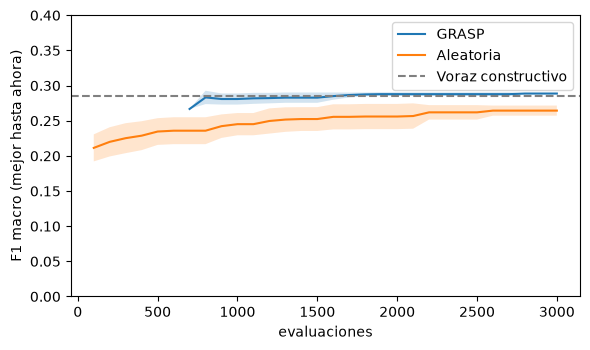

In [26]:
import numpy as np, random, matplotlib.pyplot as plt
from metric_extraction.evaluator import THETAS

# diferencias pareadas por pliegue
pv = cv.groupby(["método", "pliegue"]).macroF1.mean().unstack(0)
pv["GRASP - voraz"] = pv["GRASP"] - pv["voraz constructivo"]
pv["GRASP - aleatoria"] = pv["GRASP"] - pv["aleatoria"]
print(pv.round(3))

# convergencia en el conjunto completo (K=5, tmax=80 ms, 10 semillas)
K, TM, CP = 5, 0.080, list(range(100, 3001, 100))

def curva_grasp(seed):
    o = bl.Objective(inst, tmax=TM)
    _, tr = gr.grasp(o, n, K, 3000, alpha=0.3, seed=seed)
    return [([b for e, b in tr if e <= c] or [np.nan])[-1] for c in CP]

def curva_random(seed):
    rng, o, best, out = random.Random(seed), bl.Objective(inst, tmax=TM), -9.0, []
    for e in range(1, 3001):
        cfg = Configuration(tuple(rng.sample(range(n), rng.randint(1, K))), rng.choice(THETAS))
        best = max(best, o(cfg))
        if e in CP: out.append(best)
    return out

cg = np.array([curva_grasp(s) for s in range(10)])
cr = np.array([curva_random(s) for s in range(10)])
voraz = bl.Objective(inst, tmax=TM)(bl.greedy_forward(bl.Objective(inst, tmax=TM), n, K))

fig, ax = plt.subplots(figsize=(6, 3.6))
for nombre, c in [("GRASP", cg), ("Aleatoria", cr)]:
    m, sd = np.nanmean(c, 0), np.nanstd(c, 0)
    ax.plot(CP, m, label=nombre); ax.fill_between(CP, m - sd, m + sd, alpha=0.2)
ax.axhline(voraz, ls="--", color="gray", label="Voraz constructivo")
ax.set_xlabel("evaluaciones"); ax.set_ylabel("F1 macro (mejor hasta ahora)")
ax.set_ylim(0, 0.4); ax.legend(); fig.tight_layout()
fig.savefig("../results/figures/convergencia.png", dpi=200)
plt.show()

In [27]:
Path("../results").mkdir(exist_ok=True)
tun.to_csv("../results/ajuste_grasp.csv", index=False)
cv.to_csv("../results/validacion_cruzada.csv", index=False)
pv.to_csv("../results/diferencias_pareadas.csv")
print("guardado")

guardado
